# Step 2 — Detecting harsh driving events ourselves

**Paper:** Romera, Bergasa, Arroyo, *"Need Data for Driver Behaviour Analysis? Presenting the Public UAH-DriveSet"*, IEEE ITSC 2016.

### The idea in one paragraph
The DriveSafe app watched the phone's motion sensor and wrote down every **hard brake**, **hard acceleration**
and **sharp turn** (file `EVENTS_INERTIAL.txt`). In this step we **build our own detector** that reads the same
motion sensor data and finds these events by itself. Then we compare: did we find the same events as the app?

### How our detector works (simple version)
1. Take the motion sensor signal (10 readings per second).
   - Forward/back push (`acc_z_kf`): strongly **negative** = braking, strongly **positive** = accelerating.
   - Sideways push (`acc_y_kf`): strongly positive or negative = turning.
2. Draw a **threshold line**. Whenever the signal goes past the line, something harsh is happening.
3. If two pushes happen very close together, treat them as **one** manoeuvre.
4. The **highest point** of the push decides how bad it was: **low**, **medium** or **high**.

All the code is in `event_detection.py`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore", category=FutureWarning)

import itertools
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from uah_driveset import list_trips, load_trip
from event_detection import (DEFAULT_THRESHOLDS, add_speed, detect_events,
                             match_events, score_matches)

plt.rcParams["figure.figsize"] = (12, 4)
COLORS = {"NORMAL": "tab:green", "AGGRESSIVE": "tab:red", "DROWSY": "tab:blue"}
pd.DataFrame(DEFAULT_THRESHOLDS).T

,low,medium,high,merge_gap
braking,0.12,0.20,0.35,1.0
acceleration,0.09,0.13,0.20,3.0
turning,0.12,0.17,0.30,3.0


The table above shows our final settings (in **g**, where 1 g = the pull of gravity):
- `low` is where an event **starts**. `medium` and `high` decide how severe it is.
- `merge_gap` is how many seconds apart two pushes can be and still count as one event.

We explain in section 4 how we chose these numbers.

## 1. Load all trips

In [2]:
trips = list_trips()
trip_data = {}
for _, row in trips.iterrows():
    t = load_trip(row)
    t["accel"] = add_speed(t["accel"], t["gps"])  # attach the speed to every sensor reading
    trip_data[row.trip_id] = t
print(len(trip_data), "trips loaded")

40 trips loaded


## 2. Our detector on one trip

Driver D1, **aggressive** driving, secondary road. Each panel is one type of event:
- the **grey line** is the signal
- the **dashed line** is the threshold
- **orange dots ●** are events WE found
- **black crosses ✕** are events the APP found

When a dot and a cross sit on top of each other, we both found the same event.

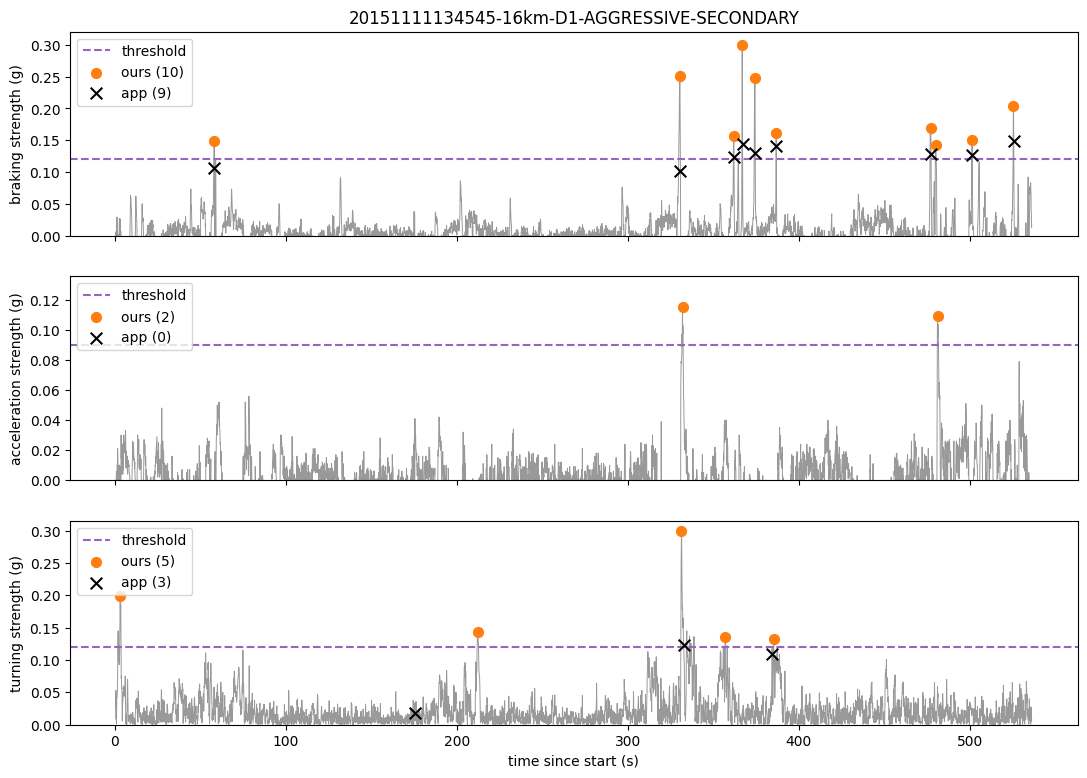

In [3]:
row = trips[(trips.driver == "D1") & (trips.behavior == "AGGRESSIVE") & (trips.road == "SECONDARY")].iloc[0]
t = trip_data[row.trip_id]
accel, app_events = t["accel"], t["events"]
our_events = detect_events(accel)

panels = [("braking", -accel["acc_z_kf"], "braking strength (g)"),
          ("acceleration", accel["acc_z_kf"], "acceleration strength (g)"),
          ("turning", accel["acc_y_kf"].abs(), "turning strength (g)")]
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, (name, signal, label) in zip(axes, panels):
    ax.plot(accel["time"], signal, color="0.6", lw=0.7)
    ax.axhline(DEFAULT_THRESHOLDS[name]["low"], ls="--", color="tab:purple", label="threshold")
    ours = our_events[our_events.event_name == name]
    theirs = app_events[app_events.event_name == name]
    peak = np.interp(ours["time"], accel["time"], signal)
    ax.scatter(ours["time"], peak, color="tab:orange", s=50, zorder=3, label=f"ours ({len(ours)})")
    ax.scatter(theirs["time"], np.interp(theirs["time"], accel["time"], signal), marker="x",
               color="black", s=70, zorder=4, label=f"app ({len(theirs)})")
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper left")
axes[-1].set_xlabel("time since start (s)")
axes[0].set_title(row.trip_id)
plt.show()

### Zooming in on one hard brake
Here we see what one braking event looks like up close: the car "pushes forward" (the
signal drops below zero) for about a second, and both detectors mark it.

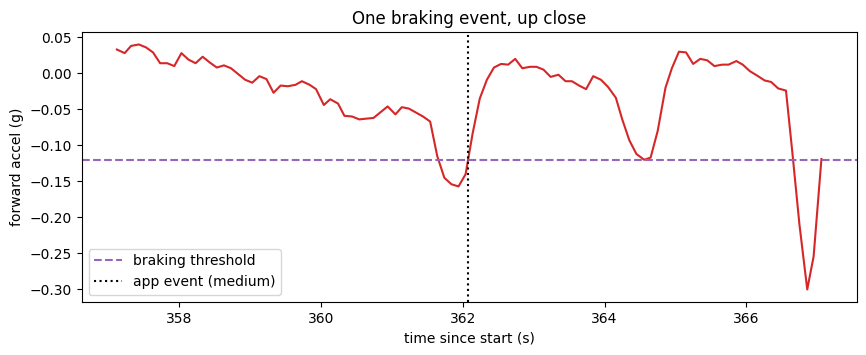

In [4]:
brake = app_events[app_events.event_name == "braking"].iloc[2]
w = accel[(accel.time > brake.time - 5) & (accel.time < brake.time + 5)]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(w["time"], w["acc_z_kf"], color="tab:red")
ax.axhline(-DEFAULT_THRESHOLDS["braking"]["low"], ls="--", color="tab:purple", label="braking threshold")
ax.axvline(brake.time, color="black", ls=":", label=f"app event ({brake.level_name})")
ax.set_xlabel("time since start (s)")
ax.set_ylabel("forward accel (g)")
ax.set_title("One braking event, up close")
ax.legend()
plt.show()

## 3. Comparing with the app on every trip

To compare, we pair each of our events with an app event of the **same type** that happened
**within 2 seconds**. Every event then ends up in one of three groups:

| Group | Meaning |
|---|---|
| **match** | both we and the app found it ✅ |
| **extra** | only we found it (the app did not) |
| **missed** | only the app found it (we did not) |

From these counts we compute three standard numbers:
- **Precision**: of the events *we* found, how many did the app also find? (Are our alarms real?)
- **Recall**: of the events the *app* found, how many did we catch? (Did we miss many?)
- **F1**: one number that balances both. **1.0 = perfect agreement**, 0 = no agreement.
- **same_level**: for matched events, how often we also agree on low / medium / high.

In [5]:
all_matches = []
for _, row in trips.iterrows():
    t = trip_data[row.trip_id]
    m = match_events(detect_events(t["accel"]), t["events"])
    m["driver"], m["trip_id"] = row.driver, row.trip_id
    all_matches.append(m)
all_matches = pd.concat(all_matches, ignore_index=True)
score_matches(all_matches)

,app_events,our_events,matched,precision,recall,f1,same_level
event,,,,,,,
acceleration,175,126,91,0.72,0.52,0.60,0.91
braking,278,232,208,0.90,0.75,0.82,0.95
turning,199,219,101,0.46,0.51,0.48,0.79


## 4. How we chose the threshold, and a fair test

If we picked the threshold by looking at **all** drivers and then tested on the same drivers, the
result would look better than it really is (like studying the exam paper before the exam).

So we did it fairly:
- **Tuning drivers: D1, D2, D3.** We tried many thresholds on them and picked the one that made the
  **fewest mistakes** (false alarms + missed events) compared with the app.
- **Test drivers: D4, D5, D6.** We never looked at them while tuning. Their result shows how well
  the detector works on **new drivers**.

The chart below shows the tuning for braking: a threshold that is too low catches lots of false
alarms (precision drops), and one that is too high misses real brakes (recall drops).
The total number of mistakes (black) is lowest in the middle.

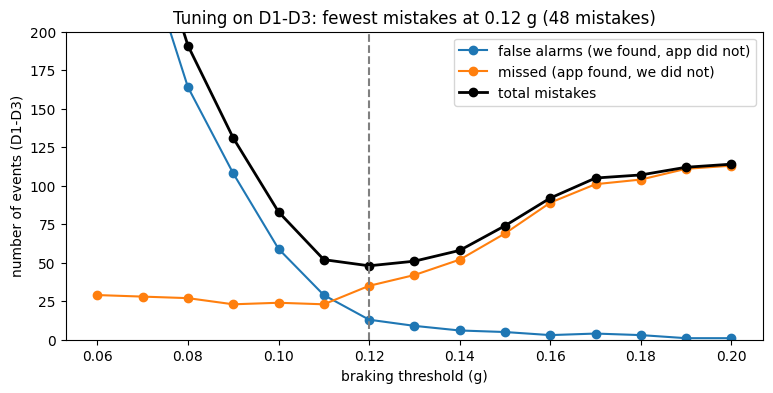

In [6]:
train_ids = trips[trips.driver.isin(["D1", "D2", "D3"])].trip_id
rows = []
for low in np.round(np.arange(0.06, 0.201, 0.01), 2):
    th = {"braking": dict(DEFAULT_THRESHOLDS["braking"], low=low)}
    m = pd.concat([match_events(detect_events(trip_data[i]["accel"], th), trip_data[i]["events"])
                   for i in train_ids])
    m = m[m.event_name == "braking"]
    rows.append({"threshold_g": low,
                 "false_alarms": (m.status == "extra").sum(),
                 "missed": (m.status == "missed").sum()})
tuning = pd.DataFrame(rows)
tuning["mistakes"] = tuning.false_alarms + tuning.missed

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tuning.threshold_g, tuning.false_alarms, marker="o", color="tab:blue", label="false alarms (we found, app did not)")
ax.plot(tuning.threshold_g, tuning.missed, marker="o", color="tab:orange", label="missed (app found, we did not)")
ax.plot(tuning.threshold_g, tuning.mistakes, marker="o", color="black", lw=2, label="total mistakes")
best = tuning.loc[tuning.mistakes.idxmin()]
ax.axvline(best.threshold_g, ls="--", color="grey")
ax.set_ylim(0, 200)
ax.set_xlabel("braking threshold (g)")
ax.set_ylabel("number of events (D1-D3)")
ax.set_title(f"Tuning on D1-D3: fewest mistakes at {best.threshold_g} g ({int(best.mistakes)} mistakes)")
ax.legend()
plt.show()


### The full tuning tables (all three event types)

The chart above shows braking only. Here is **every value we tried**, for all three event types,
on the tuning drivers D1–D3. For each candidate line we count:

- **correct**: we and the app both found the event
- **false_alarms**: we found it, the app did not
- **missed**: the app found it, we did not
- **mistakes** = false_alarms + missed

The row with the **fewest mistakes** (marked ⭐) is the value we use. F1 is shown too; it says
almost the same thing as a single score from 0 to 1 (higher = better).


In [7]:

def tune(event, lows, gaps):
    rows = []
    for low, gap in itertools.product(lows, gaps):
        th = {event: dict(DEFAULT_THRESHOLDS[event], low=round(low, 2), merge_gap=gap)}
        m = pd.concat([match_events(detect_events(trip_data[i]["accel"], th), trip_data[i]["events"])
                       for i in train_ids])
        m = m[m.event_name == event]
        s = score_matches(m).loc[event]
        rows.append({"threshold_g": round(low, 2), "merge_gap_s": gap,
                     "correct": int(s.matched), "false_alarms": int(s.our_events - s.matched),
                     "missed": int(s.app_events - s.matched),
                     "mistakes": int(s.our_events - s.matched + s.app_events - s.matched),
                     "precision": s.precision, "recall": s.recall, "f1": s.f1})
    table = pd.DataFrame(rows)
    table["best"] = np.where(table.mistakes == table.mistakes.min(), "⭐", "")
    return table

tuning_tables = {}
for event in ["braking", "acceleration", "turning"]:
    tuning_tables[event] = tune(event, np.round(np.arange(0.06, 0.161, 0.01), 2), [1.0, 2.0, 3.0])
    t = tuning_tables[event]
    for _, best in t[t.best == "⭐"].iterrows():
        print(f"{event:13s} fewest mistakes: threshold = {best.threshold_g} g, merge gap = {best.merge_gap_s} s "
              f"-> {best.mistakes} mistakes (F1 = {best.f1})")


braking       fewest mistakes: threshold = 0.12 g, merge gap = 1.0 s -> 48 mistakes (F1 = 0.82)


acceleration  fewest mistakes: threshold = 0.09 g, merge gap = 2.0 s -> 43 mistakes (F1 = 0.64)
acceleration  fewest mistakes: threshold = 0.09 g, merge gap = 3.0 s -> 43 mistakes (F1 = 0.64)


turning       fewest mistakes: threshold = 0.12 g, merge gap = 3.0 s -> 64 mistakes (F1 = 0.54)


**Braking**: each candidate line, using the best merge gap (1 s):

In [8]:

t = tuning_tables["braking"]
t[t.merge_gap_s == 1.0].drop(columns="merge_gap_s").set_index("threshold_g")


,correct,false_alarms,missed,mistakes,precision,recall,f1,best
threshold_g,,,,,,,,
0.06,114,394,29,423,0.22,0.80,0.35,
0.07,115,256,28,284,0.31,0.80,0.45,
0.08,116,164,27,191,0.41,0.81,0.55,
0.09,120,108,23,131,0.53,0.84,0.65,
0.10,119,59,24,83,0.67,0.83,0.74,
0.11,120,29,23,52,0.81,0.84,0.82,
0.12,108,13,35,48,0.89,0.76,0.82,⭐
0.13,101,9,42,51,0.92,0.71,0.80,
0.14,91,6,52,58,0.94,0.64,0.76,


**Acceleration**: each candidate line, using the best merge gap (3 s):

In [9]:

t = tuning_tables["acceleration"]
t[t.merge_gap_s == 3.0].drop(columns="merge_gap_s").set_index("threshold_g")


,correct,false_alarms,missed,mistakes,precision,recall,f1,best
threshold_g,,,,,,,,
0.06,54,196,7,203,0.22,0.89,0.35,
0.07,54,113,7,120,0.32,0.89,0.47,
0.08,51,54,10,64,0.49,0.84,0.61,
0.09,38,20,23,43,0.66,0.62,0.64,⭐
0.10,17,13,44,57,0.57,0.28,0.37,
0.11,9,3,52,55,0.75,0.15,0.25,
0.12,6,2,55,57,0.75,0.10,0.17,
0.13,4,1,57,58,0.80,0.07,0.12,
0.14,3,0,58,58,1.00,0.05,0.09,


**Turning**: each candidate line, using the best merge gap (3 s):

In [10]:

t = tuning_tables["turning"]
t[t.merge_gap_s == 3.0].drop(columns="merge_gap_s").set_index("threshold_g")


,correct,false_alarms,missed,mistakes,precision,recall,f1,best
threshold_g,,,,,,,,
0.06,48,605,11,616,0.07,0.81,0.13,
0.07,48,414,11,425,0.10,0.81,0.18,
0.08,48,251,11,262,0.16,0.81,0.27,
0.09,49,153,10,163,0.24,0.83,0.38,
0.10,47,98,12,110,0.32,0.80,0.46,
0.11,43,68,16,84,0.39,0.73,0.51,
0.12,38,43,21,64,0.47,0.64,0.54,⭐
0.13,32,39,27,66,0.45,0.54,0.49,
0.14,25,33,34,67,0.43,0.42,0.43,


**How the merge gap was chosen:** at each event's best line, we compare joining pushes that are
1, 2 or 3 seconds apart, and count the mistakes. Braking is short and sharp, so 1 s works best.
Accelerating and turning are slower movements, so joining pushes 2–3 s apart works best
(for acceleration, 2 s and 3 s tie; we use 3 s).

In [11]:

gap_rows = []
for event, low in [("braking", 0.12), ("acceleration", 0.09), ("turning", 0.12)]:
    t = tuning_tables[event]
    for _, r in t[np.isclose(t.threshold_g, low)].iterrows():
        gap_rows.append({"event": event, "threshold_g": low, "merge_gap_s": r.merge_gap_s,
                         "mistakes": r.mistakes, "f1": r.f1})
pd.DataFrame(gap_rows).pivot(index="event", columns="merge_gap_s", values="mistakes")


merge_gap_s,1.0,2.0,3.0
event,,,
acceleration,45,43,43
braking,48,49,51
turning,77,68,64


In [12]:
test = all_matches[~all_matches.driver.isin(["D1", "D2", "D3"])]
print("Result on the TEST drivers D4, D5, D6 (not used for tuning):")
score_matches(test)

Result on the TEST drivers D4, D5, D6 (not used for tuning):


,app_events,our_events,matched,precision,recall,f1,same_level
event,,,,,,,
acceleration,114,68,53,0.78,0.46,0.58,0.89
braking,135,111,100,0.90,0.74,0.81,0.99
turning,140,138,63,0.46,0.45,0.45,0.76


### Do we agree on how severe each event was?
For events we both found, rows are the app's level and columns are ours. Most events sit on the
diagonal, which means we agree.

In [13]:
matched = all_matches[all_matches.status == "match"]
for name in ["braking", "acceleration", "turning"]:
    m = matched[matched.event_name == name]
    print(f"\n{name.upper()}")
    print(pd.crosstab(m.app_level, m.our_level, rownames=["app"], colnames=["ours"]))


BRAKING
ours    high  low  medium
app                      
high       5    0       0
low        0  160       2
medium     6    2      33

ACCELERATION
ours    low  medium
app                
low      81       7
medium    1       2

TURNING
ours    high  low  medium
app                      
low        0   66      17
medium     2    2      14


## 5. The part that matters most: whole trips

For a driver score we don't need to match every single event perfectly. What matters is whether
we count **roughly the same number of harsh events per trip** as the app, and whether those counts
tell **normal**, **drowsy** and **aggressive** driving apart.

We count events **per 10 km**, so long and short trips can be compared fairly.

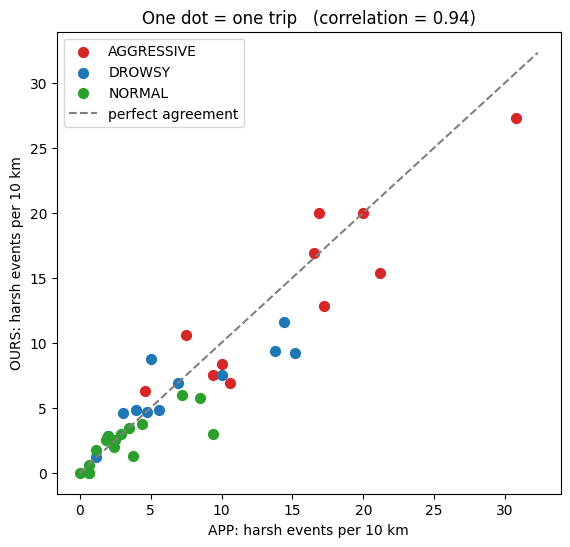

In [14]:
per_trip = []
for _, row in trips.iterrows():
    t = trip_data[row.trip_id]
    ours = detect_events(t["accel"])
    rec = {"trip_id": row.trip_id, "driver": row.driver, "behavior": row.behavior,
           "road": row.road, "distance_km": row.distance_km}
    for name in ["braking", "acceleration", "turning"]:
        rec[f"{name}_per10km"] = (ours.event_name == name).sum() / row.distance_km * 10
        rec[f"{name}_high_med_per10km"] = ((ours.event_name == name) &
                                           ours.level_name.isin(["medium", "high"])).sum() / row.distance_km * 10
    rec["our_events_per10km"] = len(ours) / row.distance_km * 10
    rec["app_events_per10km"] = len(t["events"]) / row.distance_km * 10
    per_trip.append(rec)
per_trip = pd.DataFrame(per_trip)

corr = per_trip.our_events_per10km.corr(per_trip.app_events_per10km)
fig, ax = plt.subplots(figsize=(6.5, 6))
for b, g in per_trip.groupby("behavior"):
    ax.scatter(g.app_events_per10km, g.our_events_per10km, color=COLORS[b], label=b, s=50)
lim = per_trip[["app_events_per10km", "our_events_per10km"]].max().max() * 1.05
ax.plot([0, lim], [0, lim], ls="--", color="grey", label="perfect agreement")
ax.set_xlabel("APP: harsh events per 10 km")
ax.set_ylabel("OURS: harsh events per 10 km")
ax.set_title(f"One dot = one trip   (correlation = {corr:.2f})")
ax.legend()
plt.show()

Every dot is one trip. The dots sit close to the dashed line, so our counts follow the app's
counts very closely (**correlation close to 1** means near-perfect agreement).
The red (aggressive) dots are clearly at the top right, far away from the green (normal) ones.

In [15]:
table = per_trip.groupby("behavior")[["braking_per10km", "acceleration_per10km", "turning_per10km",
                                      "our_events_per10km", "app_events_per10km"]].mean().round(2)
table.loc[["NORMAL", "DROWSY", "AGGRESSIVE"]]

,braking_per10km,acceleration_per10km,turning_per10km,our_events_per10km,app_events_per10km
behavior,,,,,
NORMAL,0.80,0.35,1.27,2.41,3.14
DROWSY,2.31,0.81,3.24,6.35,7.15
AGGRESSIVE,6.21,3.98,3.63,13.82,14.97


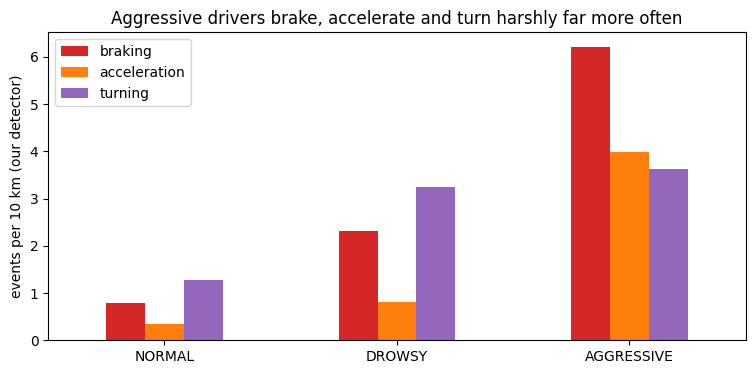

In [16]:
order = ["NORMAL", "DROWSY", "AGGRESSIVE"]
cols = ["braking_per10km", "acceleration_per10km", "turning_per10km"]
means = per_trip.groupby("behavior")[cols].mean().loc[order]
ax = means.plot.bar(figsize=(9, 4), rot=0, color=["tab:red", "tab:orange", "tab:purple"])
ax.set_ylabel("events per 10 km (our detector)")
ax.set_xlabel("")
ax.set_title("Aggressive drivers brake, accelerate and turn harshly far more often")
ax.legend(["braking", "acceleration", "turning"])
plt.show()

### Save the results for the next steps
These per-trip numbers become **features** (inputs) for the classifier and the safety score later.

In [17]:
from pathlib import Path
Path("../results").mkdir(exist_ok=True)
per_trip.to_csv("../results/step2_trip_events.csv", index=False)
per_trip.head()

,trip_id,driver,behavior,road,distance_km,braking_per10km,braking_high_med_per10km,acceleration_per10km,acceleration_high_med_per10km,turning_per10km,turning_high_med_per10km,our_events_per10km,app_events_per10km
0,20151110175712-16km-D1-NORMAL1-SECONDARY,D1,NORMAL,SECONDARY,16,0.000000,0.00,0.0,0.0,2.500000,0.625,2.50,1.875000
1,20151110180824-16km-D1-NORMAL2-SECONDARY,D1,NORMAL,SECONDARY,16,2.500000,0.00,0.0,0.0,1.250000,0.625,3.75,4.375000
2,20151111123124-25km-D1-NORMAL-MOTORWAY,D1,NORMAL,MOTORWAY,25,1.200000,0.00,0.0,0.0,0.800000,0.400,2.00,2.400000
3,20151111125233-24km-D1-AGGRESSIVE-MOTORWAY,D1,AGGRESSIVE,MOTORWAY,24,2.916667,1.25,0.0,0.0,3.333333,1.250,6.25,4.583333
4,20151111132348-25km-D1-DROWSY-MOTORWAY,D1,DROWSY,MOTORWAY,25,2.800000,1.60,0.0,0.0,2.000000,1.200,4.80,4.000000


## 6. Why don't we match 100%?

- **Braking matches well** (F1 ≈ 0.8, and ≈ 99% agreement on severity for new drivers). Braking is a
  clear, strong forward push and easy to detect.
- **Acceleration is moderate.** Speeding up is gentler and longer than braking, so it is harder to
  say exactly where one event starts and ends.
- **Turning matches least.** The app uses extra rules the paper doesn't fully describe. For example,
  it never reported a turn below about 50 km/h, and it skipped some turns that were *stronger* than
  ones it did report. It likely also uses the road's shape, since a curve on the motorway is normal
  but a swerve is not. With only the accelerometer, we can't copy those hidden rules exactly.

**But for scoring a driver, the per-trip totals are what count, and those agree very well
(correlation ≈ 0.94).**

## Summary

| What | Result |
|---|---|
| Built our own detector | threshold + merge + peak level, in `event_detection.py` |
| Fair test (tuned on D1–D3, tested on D4–D6) | braking F1 ≈ 0.81, acceleration ≈ 0.58, turning ≈ 0.45 |
| Severity agreement on matched events | ≈ 90–99% for braking and acceleration |
| Per-trip event rate vs the app | correlation ≈ 0.94 |
| Events per 10 km | Normal ≈ 2.4, Drowsy ≈ 6.4, Aggressive ≈ 13.8 |

**Next step (Step 3):** add the other behaviours the paper uses: **speeding** (GPS speed vs
OpenStreetMap speed limit), **tailgating** (distance to the car ahead) and **lane drifting / weaving**
(lane camera).